In [1]:
import matplotlib.pyplot as plt
import numpy as np

from experiments.linear.setup import setup

from rp_slam import datasets
from rp_slam.training import Trainer
from rp_slam.recognition.networks import MLP
from rp_slam.utils.nnreg import DecoderNetwork, DecoderTrainer, Config as DecoderConfig

## Helper Functions

In [2]:
def train(
    kernel: str,
    latent_dim: int = 16,
    batch_size: int = 32,
    num_iter: int = 2500,
    seed: int = 1234,
    prior_lr: float = 5e-4,
    rec_lr: float = 5e-4,
    plot: bool = True
):
    
    CONFIG, MODEL_FE = setup(
        kernel=kernel,
        latent_dim=latent_dim, 
        batch_size=batch_size, 
        num_iter=num_iter, 
        seed=seed,
        prior_lr=prior_lr, 
        rec_lr=rec_lr
    )
    
    trainer = Trainer(model=MODEL_FE, config=CONFIG)
    trainer.fit(data=DATASET.train_data, use_pbar=True)

    # plot loss over time
    if plot:
        plt.figure(figsize=(14, 3))
        plt.plot(trainer.loss_tot)
        plt.title("Training loss over iterations")
        plt.xlabel("Iteration")
        plt.ylabel("Loss")
        plt.show()
    
    return trainer

In [3]:
def neural_regression(
    y,
    val_y,
    batch_size: int = 32,
    iterations: int = 10000,
    seed: int = 8234,
    patience: int = 1000,
    lr: float = 1e-3,
    plot: bool = True
):
    DEC_CFG = DecoderConfig(
        batch_size=batch_size,
        iterations=iterations,
        seed=seed,
        patience=patience,
        lr=lr
    )
    decoder = DecoderNetwork(MLP([64, 64, 64]), output_dim=DATASET.train_states.shape[-1])
    
    nn_reg = DecoderTrainer(model=decoder, config=DEC_CFG)
    nn_reg.fit(DATASET.train_states, y, DATASET.val_states, val_y)

    if plot:
        plt.figure(figsize=(14, 3))
        plt.plot(nn_reg.loss_tot)
        plt.title("Neural Regression Loss over Iterations")
        plt.xlabel("Iteration")
        plt.ylabel("SSE")
        plt.show()
        
        plt.figure(figsize=(14, 3))
        plt.plot(nn_reg.val_loss_tot)
        plt.title("Neural Regression Validation Loss over Iterations")
        plt.xlabel("Iteration")
        plt.ylabel("SSE")
        plt.show()

    return nn_reg

In [4]:
def plot_visual_diagnostics(preds, truth, B: int = 3):

    preds = np.asarray(preds)
    truth = np.asarray(truth)
    D = preds.shape[-1]
    K =truth.shape[-1]

    # plot example regressions
    for b in range(B):
        fig, ax = plt.subplots(1, K, figsize=(15, 2))
        for k in range(K):
            ax[k].plot(DATASET.val_states[b, :, k], label="Truth")
            ax[k].plot(preds[b, :, k], label="Predicted")
            ax[k].legend(fontsize=6)
    plt.show()

    # plot fit 
    fig, axes = plt.subplots(1, D, figsize=(4 * D, 4), squeeze=False)
    
    for d, ax in enumerate(axes.ravel()):
        x = truth[:, :, d].ravel()
        y = preds[:, :, d].ravel()
    
        # Least-squares line of best fit
        slope, intercept = np.polyfit(x, y, 1)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = slope * x_fit + intercept
    
        # R-squared
        r2 = 1 - np.sum((y - (slope * x + intercept))**2) / np.sum((y - y.mean())**2)
    
        ax.scatter(x, y, s=3, alpha=0.3)
        ax.plot(x_fit, y_fit, color="red", lw=1.5, label=f"Fit ($R^2={r2:.3f}$)")
        ax.plot(x_fit, x_fit, "k--", lw=1, label="Ideal")
    
        ax.set_title(f"Dimension {d + 1}")
        ax.set_xlabel("Truth")
        ax.set_ylabel("Predicted")
        ax.legend(fontsize=12)
    
    plt.tight_layout()
    plt.show()
    

## Linear Dataset

In [5]:
DATASEED = 0
DATASET = datasets.load_dataset("linear_medium", DATASEED)
DATASET = DATASET.standardized_data

## RPSSM

Training: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [02:50<00:00, 14.70it/s, loss=1.6]


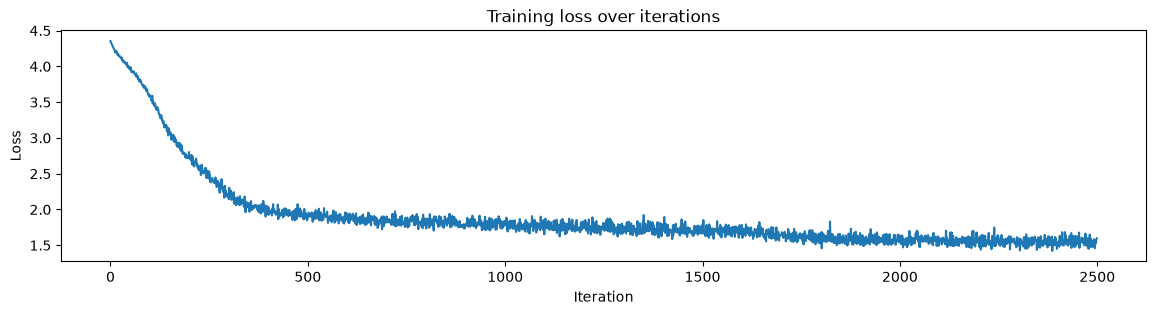

In [6]:
trainer = train(kernel="rpssm")

Training Decoder with N=200, T=100


 43%|██████████████████████████████████████████████████████████▋                                                                            | 4343/10000 [01:18<01:42, 55.44it/s, loss=0.062]


Early stopping at iteration 4343 with best validation loss 2220.178


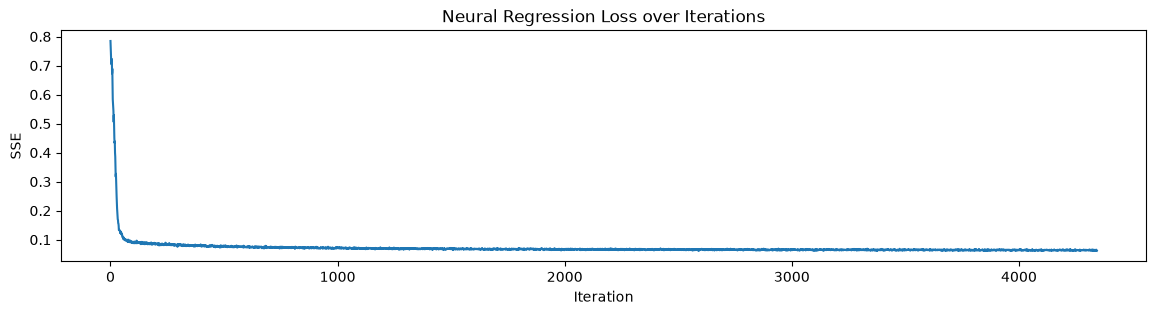

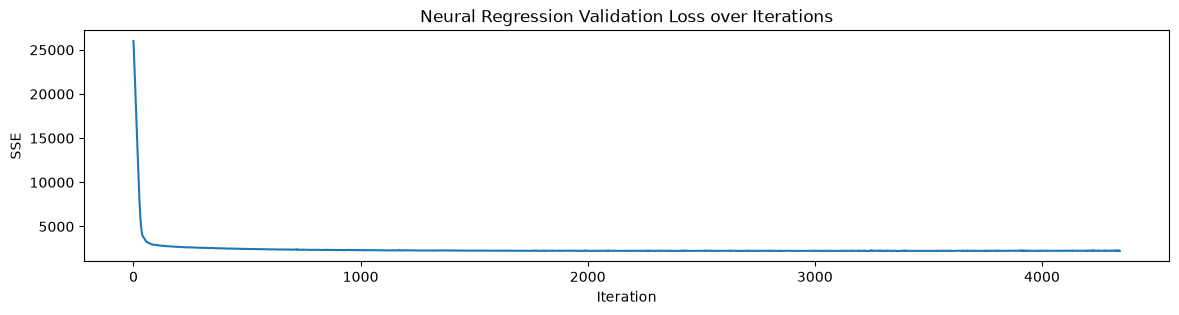

In [7]:
y = trainer.apply(DATASET.train_data).params["means"]
val_y = trainer.apply(DATASET.val_data).params["means"]
nn_reg = neural_regression(y, val_y)

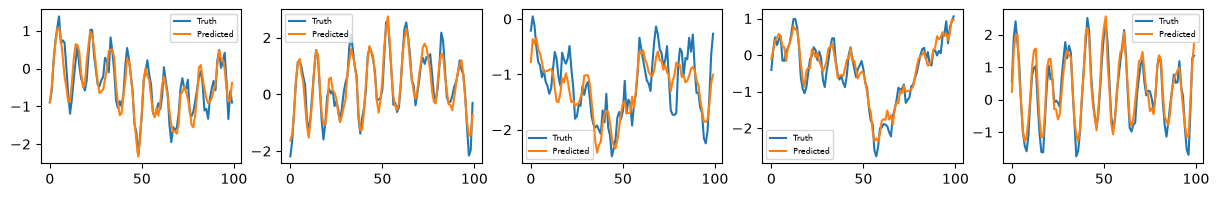

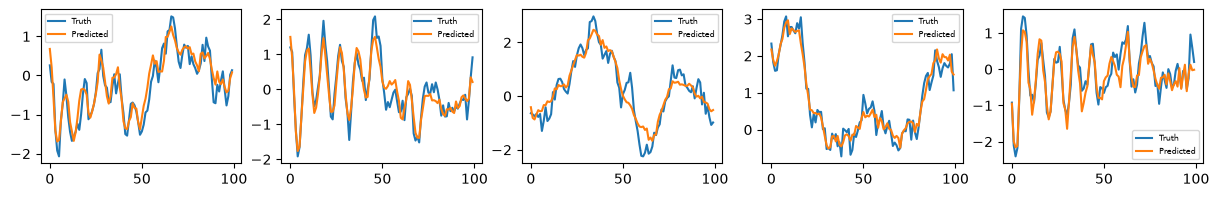

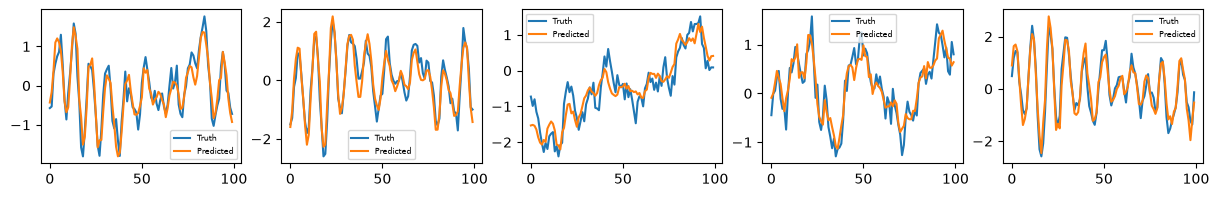

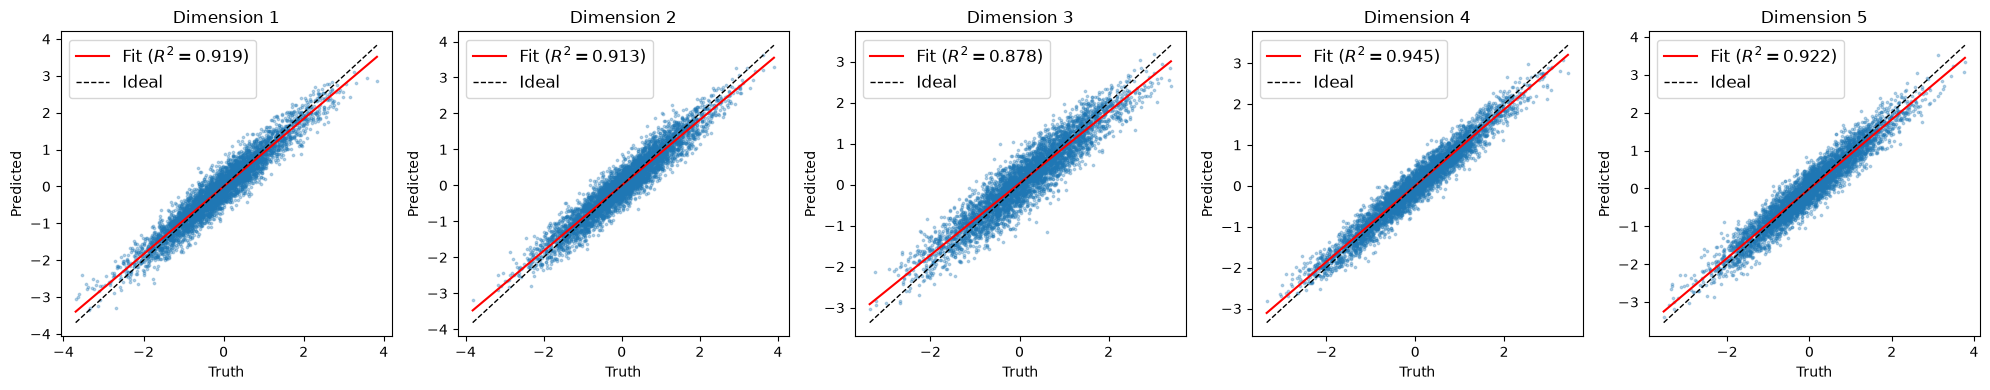

In [8]:
preds = nn_reg.apply(nn_reg.params, val_y)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)

## RAMPSSM

Training: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [04:00<00:00, 10.38it/s, loss=-2.85]


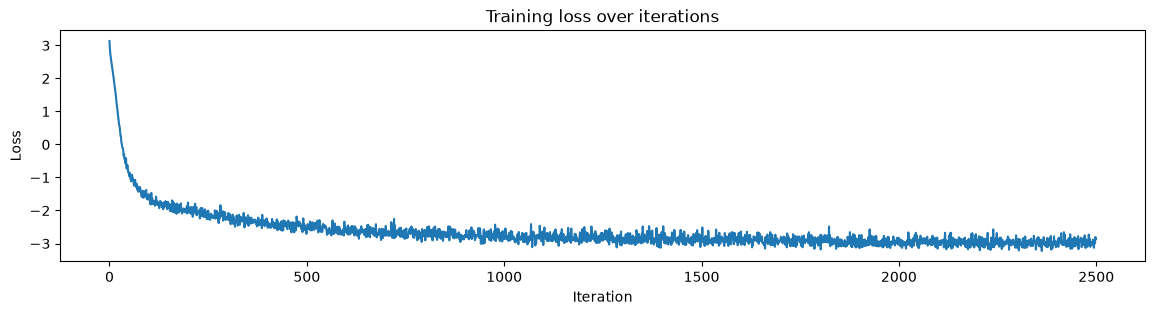

In [9]:
trainer = train(kernel="ramp")

Training Decoder with N=200, T=100


 60%|████████████████████████████████████████████████████████████████████████████████▋                                                      | 5980/10000 [01:44<01:09, 57.49it/s, loss=0.041]


Early stopping at iteration 5980 with best validation loss 1450.311


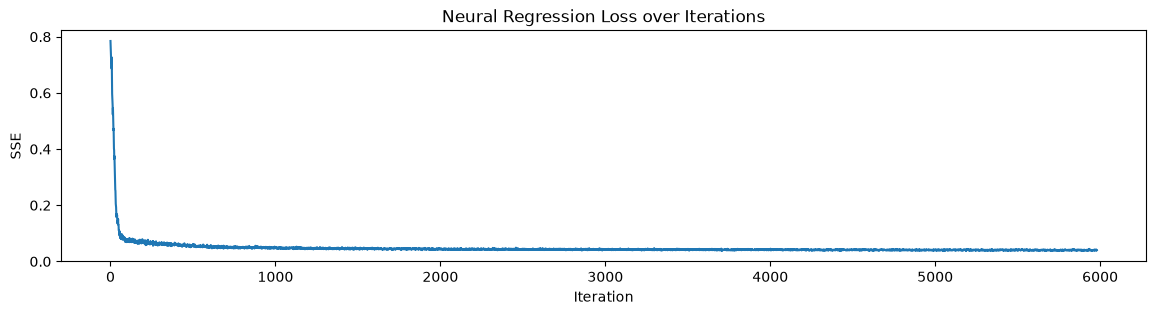

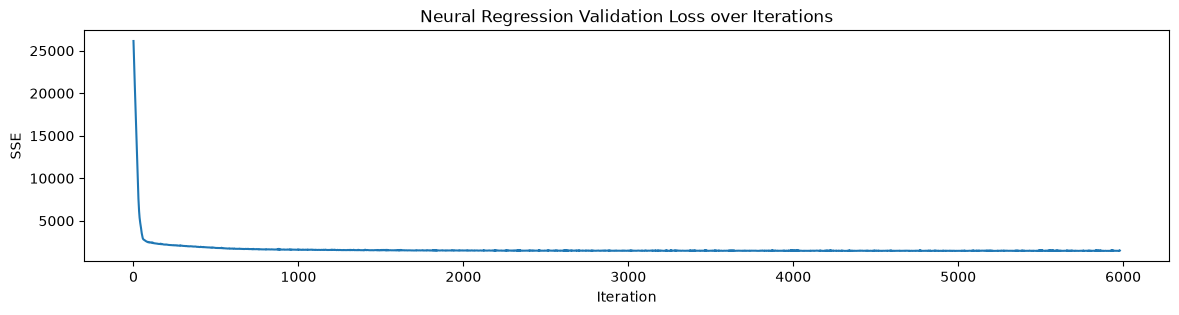

In [10]:
y = trainer.apply(DATASET.train_data).params["mean"]
val_y = trainer.apply(DATASET.val_data).params["mean"]
nn_reg = neural_regression(y, val_y)

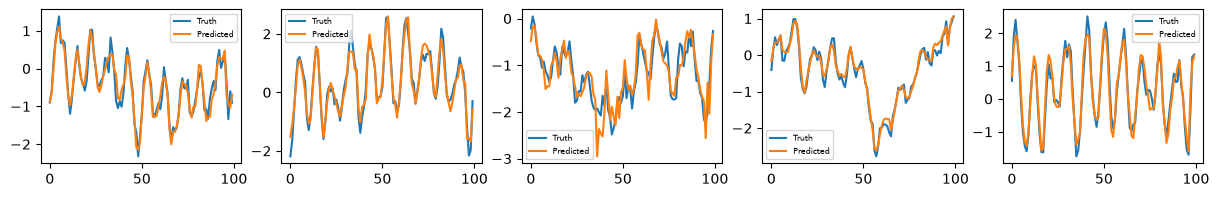

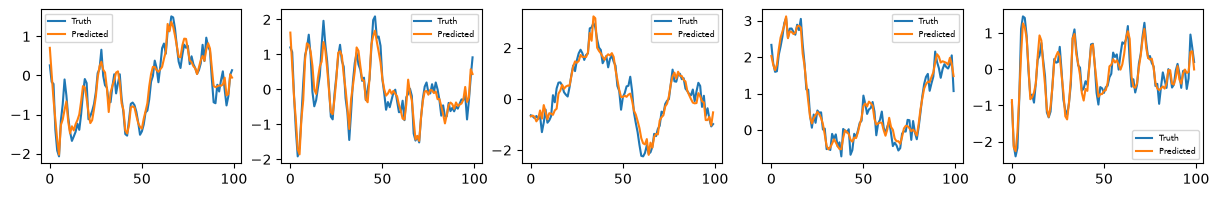

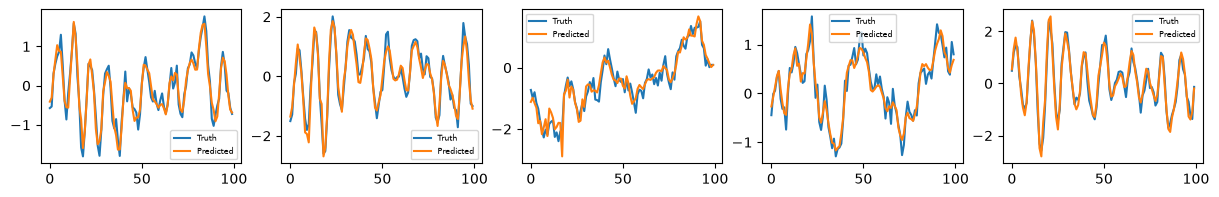

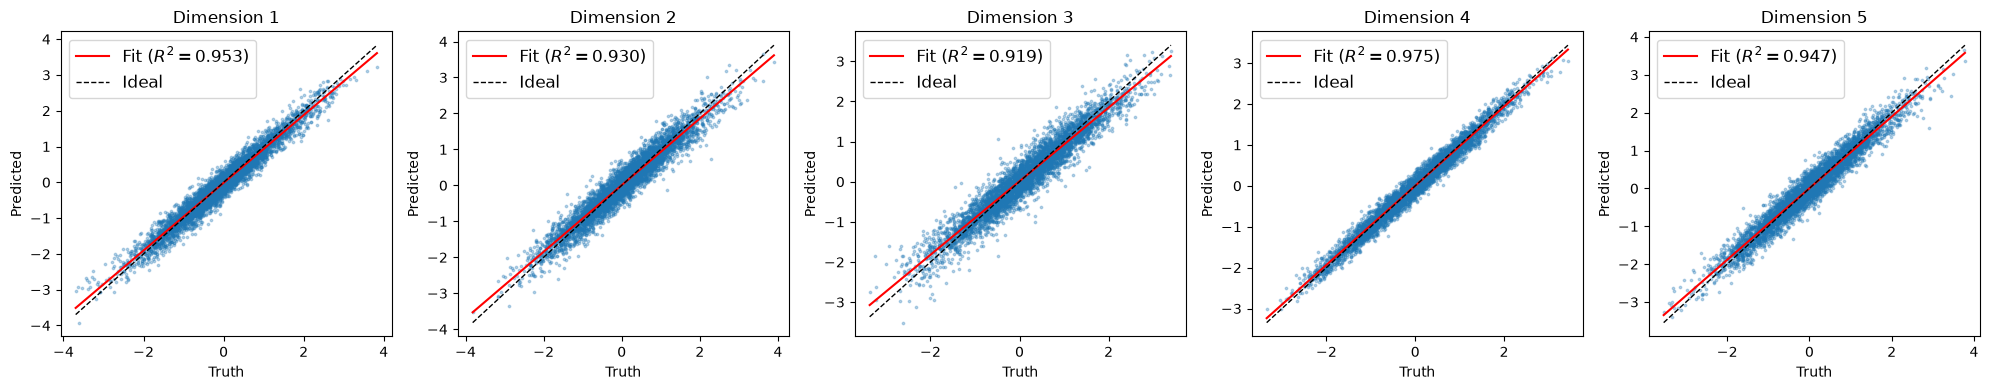

In [12]:
preds = nn_reg.apply(nn_reg.params, val_y)
truth = DATASET.val_states
plot_visual_diagnostics(preds, truth)